In [1]:
import pandas as pd
import numpy as np

df2 = pd.read_csv("dataset_phishing.csv", low_memory=False)   # use your actual file name
print("Shape:", df2.shape)
print("Columns:", df2.columns[-3:].tolist())

# Drop the raw URL text (SVM needs numbers)
if "url" in df2.columns:
    df2 = df2.drop(columns=["url"])

# Encode the label: phishing = 1, legitimate = 0
df2["status"] = df2["status"].map({"legitimate": 0, "phishing": 1})
df2 = df2.dropna()

X2 = df2.drop(columns=["status"])
y2 = df2["status"]

print("X shape:", X2.shape)
print("Class balance:\n", y2.value_counts())

Shape: (11430, 89)
Columns: ['google_index', 'page_rank', 'status']
X shape: (11430, 87)
Class balance:
 status
0    5715
1    5715
Name: count, dtype: int64


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

scaler2 = StandardScaler()
X2_train_s = scaler2.fit_transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

print("Train:", X2_train_s.shape, "Test:", X2_test_s.shape)

Train: (9144, 87) Test: (2286, 87)


In [3]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

kernels = {
    "Linear": SVC(kernel="linear", C=1),
    "Polynomial": SVC(kernel="poly", degree=3, C=1),
    "RBF": SVC(kernel="rbf", C=1, gamma="scale"),
}

for name, model in kernels.items():
    model.fit(X2_train_s, y2_train)
    acc = accuracy_score(y2_test, model.predict(X2_test_s))
    print(f"{name:10s} accuracy: {acc:.4f}")

Linear     accuracy: 0.9401
Polynomial accuracy: 0.9449
RBF        accuracy: 0.9541


In [4]:
from sklearn.model_selection import GridSearchCV

param_grid = {"C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.001]}

grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=3, n_jobs=-1)
grid.fit(X2_train_s, y2_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Best parameters: {'C': 10, 'gamma': 0.01}
Best CV accuracy: 0.9581


Test accuracy: 0.9624

              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1143
    Phishing       0.96      0.96      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



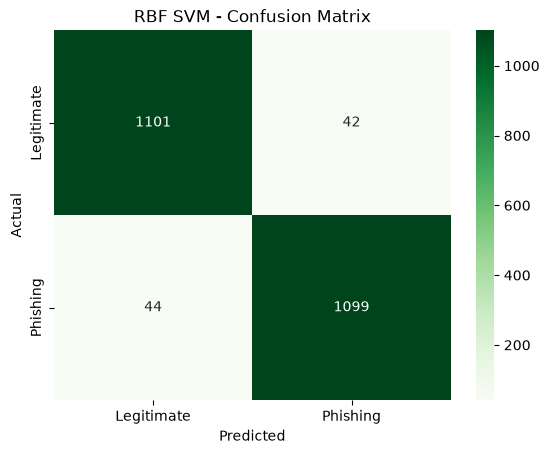

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

best_svm = grid.best_estimator_
y2_pred = best_svm.predict(X2_test_s)

print("Test accuracy:", round(accuracy_score(y2_test, y2_pred), 4))
print()
print(classification_report(y2_test, y2_pred, target_names=["Legitimate", "Phishing"]))

cm2 = confusion_matrix(y2_test, y2_pred)
sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Legitimate", "Phishing"],
            yticklabels=["Legitimate", "Phishing"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RBF SVM - Confusion Matrix")
plt.show()